# "likes" report

Name: Christian Anderson  
Date: 09/23/26

The source of my data is Instagram. I downloaded the data from my own Instagram account, but I did not create it. The data was created automatically by Instagram.

The data was created to record my activity and interactions on Instagram. Instagram can use this data to personalize my experience and keep a record of my activity. I can also use the data to analyze my own Instagram habits and behavior.

This data can be reliable because it comes directly from my Instagram account and is automatically recorded by the platform. The timestamps and other activity information are generated from my actual interactions with Instagram.

The data can be unreliable because it may not include every detail about how I used Instagram, and some of the information may be difficult to understand because of the way Instagram organizes and exports the data.

In [31]:
import json
import pandas as pd

with open('liked_posts.json', 'r') as f:
    data = json.load(f)

data[0]

{'timestamp': 1790120406,
 'media': [],
 'label_values': [{'label': 'URL',
   'value': 'https://www.instagram.com/p/Ddm1WL-gCsc/',
   'href': 'https://www.instagram.com/p/Ddm1WL-gCsc/'},
  {'label': 'Caption',
   'value': 'Game, Set, MATCH! ð\x9f\x8e¾\n\nð\x9f\x93¸ - @trellvisuals'},
  {'label': 'Title', 'value': ''},
  {'dict': [], 'title': 'Hashtags'},
  {'dict': [{'dict': [{'label': 'URL',
       'value': 'https://linktr.ee/morganimani'},
      {'label': 'Name', 'value': 'Morgalicious ð\x9f\x8e\x80'},
      {'label': 'Username', 'value': 'themorganimani'}],
     'title': ''}],
   'title': 'Owner'},
  {'dict': [], 'title': 'Brand partner'}],
 'fbid': '18258984175307633'}

In [32]:
row = {}
row['timestamp'] = data[0]['timestamp']
row

{'timestamp': 1790120406}

In [33]:
for item in data[0]['label_values']:
    if 'label' in item:
        row[item['label']] = item['value']
row

{'timestamp': 1790120406,
 'URL': 'https://www.instagram.com/p/Ddm1WL-gCsc/',
 'Caption': 'Game, Set, MATCH! ð\x9f\x8e¾\n\nð\x9f\x93¸ - @trellvisuals',
 'Title': ''}

In [34]:
for item in data[0]['label_values']:
    if 'label' in item:
        row[item['label']] = item['value']
    elif item.get('title') == 'Owner':
        owner_fields = item['dict'][0]['dict']
        for owner_item in owner_fields:
            row['Owner ' + owner_item['label']] = owner_item['value']

row

{'timestamp': 1790120406,
 'URL': 'https://www.instagram.com/p/Ddm1WL-gCsc/',
 'Caption': 'Game, Set, MATCH! ð\x9f\x8e¾\n\nð\x9f\x93¸ - @trellvisuals',
 'Title': '',
 'Owner URL': 'https://linktr.ee/morganimani',
 'Owner Name': 'Morgalicious ð\x9f\x8e\x80',
 'Owner Username': 'themorganimani'}

In [35]:
tidy_rows = []

for entry in data:
    row = {}
    row['timestamp'] = entry['timestamp']

    for item in entry['label_values']:
        if 'label' in item:
            row[item['label']] = item['value']
        elif item.get('title') == 'Owner':
            owner_fields = item['dict'][0]['dict']
            for owner_item in owner_fields:
                row['Owner ' + owner_item['label']] = owner_item['value']
    tidy_rows.append(row)

tidy_rows[2]   

{'timestamp': 1789956606,
 'URL': 'https://www.instagram.com/p/DdhUD7gJuPi/',
 'Caption': 'ð\x9f\x9a¨â\x80¼ï¸\x8f @motion_universal_ & @bigmotion2456ð\x9f\x8e¥\n \nPRESENTS ð\x9f\x94¥ KENT HOMECOMING \nAFTER PARTYâ\x80\x94 @mrscubaa LIVE! ð\x9f\x8e¤ð\x9f\x95ºð\x9f\x8f¾\n\nð\x9f\x93\x85 Saturday, October 3rd\n\nð\x9f\x93\x8d The Outpost â\x80\x94 4962 OH-43, Kent, Ohio 44240\n\nHosted by : Arrogant Cass, KSU Flashettes & Savage Dawgs \n\nð\x9f\x8e\x9fï¸\x8f $20 DOOR ADMISSION TIL INFLATION\nâ\x9a\xa0ï¸\x8f RSVP TICKETS ARE SOLD OUT â\x80\x94 RSVP tickets will be accepted at the door, but expire at 10:30 PM. â\x8f°\n\nð\x9f\x94¥â\x80¼ï¸\x8fð\x9f\x8e¥KENT HOMECOMING WEEKEND â\x80\x94 WE OUTSIDE!',
 'Title': '',
 'Owner URL': '',
 'Owner Name': 'Bigmotion1457',
 'Owner Username': 'bigmotion1567'}

In [36]:
likes_df = pd.DataFrame(tidy_rows)
likes_df.head(10)

,timestamp,URL,Caption,Title,Owner URL,Owner Name,Owner Username
0,1790120406,https://www.instagram.com/p/Ddm1WL-gCsc/,"Game, Set, MATCH! ð¾\n\nð¸ - @trellvisuals",,https://linktr.ee/morganimani,Morgalicious ð,themorganimani
1,1790097036,https://www.instagram.com/p/DdlH5kKlvEb/,you da goat girl â¤ï¸! \n\nthe dopest girl ð...,,https://www.fresha.com/book-now/styledbymarah-...,jemarah ð«¶ð½,itss.marxh
2,1789956606,https://www.instagram.com/p/DdhUD7gJuPi/,ð¨â¼ï¸ @motion_universal_ & @bigmotion2456...,,,Bigmotion1457,bigmotion1567
3,1789956544,https://www.instagram.com/p/DdhdHA3IPDM/,"more to grow, more to beð¥\n-\n-\n-\n-\n\nâ...",,,sherie <3,sherylyeboahh
4,1789956520,https://www.instagram.com/p/DdhbYelGtas/,ð¬ð§,,https://youtube.com/@jayteryx,ð´ââ ï¸,jayteryx
5,1789956372,https://www.instagram.com/reel/Ddh_-HgRdPGvlol...,A beautiful way to end the weekend with a Sist...,,,Karli Karly Karleeð¥°,its_karli_baybee
6,1789928260,https://www.instagram.com/reel/DdhC3NVSePC/,Male Stitch ð¥·ð½ððððððð...,,https://lnk.bio/BinsuiLUXE,"HEY, IM MKð",binsuistyles
7,1789846176,https://www.instagram.com/p/DdegoYdjKKJ/,I just love a wedding! ð,,,,simiayobee
8,1789846160,https://www.instagram.com/p/Ddd44OEDOZV/,More weddings please ð¥,,,Teniiið¤©â¼ï¸,qxeen_teni
9,1789688022,https://www.instagram.com/p/DdXwUZtEbq3/,ð\n.\n.\n.\n.\n#explorepageâ¨ #makethisgov...,,https://youtube.com/@khirice_?si=pXsJqYDJFWGISz9O,ð²ðð,khirice


In [37]:
likes_df['DateTime'] = pd.to_datetime(likes_df['timestamp'], unit='s')
likes_df[['timestamp', 'DateTime']].head()

,timestamp,DateTime
0,1790120406,2026-09-22 23:40:06
1,1790097036,2026-09-22 17:10:36
2,1789956606,2026-09-21 02:10:06
3,1789956544,2026-09-21 02:09:04
4,1789956520,2026-09-21 02:08:40


In [38]:
likes_df.shape

(8102, 8)

In [39]:
likes_df['Owner Username'].isna().sum()

np.int64(0)

In [40]:
likes_df.dtypes

timestamp                 int64
URL                         str
Caption                     str
Title                       str
Owner URL                   str
Owner Name                  str
Owner Username              str
DateTime          datetime64[s]
dtype: object

In [41]:
likes_df.groupby("Owner Username")["DateTime"].count()

Owner Username
04b4by            1
0fficial_.vaeh    1
0fxckzs           1
1.asiapt2_        1
11.leonjones      3
                 ..
zodiacdsign       1
zoe2tuff          1
zoomaburst        1
zoraase           6
zuriponzzz        1
Name: DateTime, Length: 1192, dtype: int64

In [42]:
likes_by_account = (
    likes_df.groupby("Owner Username") ["DateTime"]
    .count()
    .sort_values(ascending=False)
)
likes_by_account.head(10)

Owner Username
theshaderoom         2313
theshaderoomteens     831
worldstar             345
gucci.bops            265
stiffmoods            173
jordansnut            159
niccaup               145
brainofbreeze         120
jay.nedaj              86
bitch                  85
Name: DateTime, dtype: int64

In [43]:
with open('polls.json', 'r') as f:
    polls = json.load(f)

polls[0]

{'timestamp': 1780276860,
 'media': [],
 'label_values': [{'label': 'Option 1', 'value': 'Yes'},
  {'label': 'Option 2', 'value': 'No'},
  {'label': 'Option 3', 'value': ''},
  {'label': 'Option 4', 'value': ''},
  {'label': 'Option 1 font size', 'value': '16'},
  {'label': 'Option 2 font size', 'value': '16'},
  {'label': 'Option 3 font size', 'value': '35'},
  {'label': 'Option 4 font size', 'value': '35'},
  {'label': 'Color', 'value': 'Black'},
  {'label': 'Question',
   'value': 'IS IT POSSIBLE TO STACK 10â\x80\x9315K WORKING A JOB ?'},
  {'label': 'Anonymous poll', 'value': 'False'},
  {'label': 'Type', 'value': 'Story poll'},
  {'label': 'Expiration time', 'timestamp_value': 0},
  {'label': 'URL',
   'value': 'https://www.instagram.com/stories/arrogant_cass/3909343776224913947',
   'href': 'https://www.instagram.com/stories/arrogant_cass/3909343776224913947'},
  {'label': 'Caption',
   'value': 'Yâ\x80\x99all Iâ\x80\x99m arguing with somebody so please tell me if Iâ\x80\x99m wro

My hypothesis is that I interact with some Instagram accounts story polls more than others.

In [44]:
polls[1]

{'timestamp': 1776661623,
 'media': [],
 'label_values': [{'label': 'Option 1', 'value': 'Yes'},
  {'label': 'Option 2', 'value': 'No'},
  {'label': 'Option 3', 'value': ''},
  {'label': 'Option 4', 'value': ''},
  {'label': 'Option 1 font size', 'value': '12'},
  {'label': 'Option 2 font size', 'value': '12'},
  {'label': 'Option 3 font size', 'value': '35'},
  {'label': 'Option 4 font size', 'value': '35'},
  {'label': 'Color', 'value': 'Black'},
  {'label': 'Question', 'value': 'CF'},
  {'label': 'Anonymous poll', 'value': 'False'},
  {'label': 'Type', 'value': 'Default'},
  {'label': 'Expiration time', 'timestamp_value': 0},
  {'label': 'URL',
   'value': 'https://www.instagram.com/stories/2thrusted/3879167070055477360',
   'href': 'https://www.instagram.com/stories/2thrusted/3879167070055477360'},
  {'dict': [], 'title': 'Hashtags'},
  {'dict': [{'dict': [{'label': 'URL', 'value': ''},
      {'label': 'Name', 'value': ''},
      {'label': 'Username', 'value': '2thrusted'}],
     '

In [45]:
poll_rows = []

for entry in polls:
    row = {}
    row['timestamp'] = entry['timestamp']

    for item in entry['label_values']:
        if 'label' in item and 'value' in item:
            row[item['label']] = item['value']
        elif item.get('title') == 'Owner':
            owner_fields = item['dict'][0]['dict']
            for owner_item in owner_fields:
                row['Owner ' + owner_item['label']] = owner_item['value']

    poll_rows.append(row)

poll_rows[0]

{'timestamp': 1780276860,
 'Option 1': 'Yes',
 'Option 2': 'No',
 'Option 3': '',
 'Option 4': '',
 'Option 1 font size': '16',
 'Option 2 font size': '16',
 'Option 3 font size': '35',
 'Option 4 font size': '35',
 'Color': 'Black',
 'Question': 'IS IT POSSIBLE TO STACK 10â\x80\x9315K WORKING A JOB ?',
 'Anonymous poll': 'False',
 'Type': 'Story poll',
 'URL': 'https://www.instagram.com/stories/arrogant_cass/3909343776224913947',
 'Caption': 'Yâ\x80\x99all Iâ\x80\x99m arguing with somebody so please tell me if Iâ\x80\x99m wrong.  I said yes but itâ\x80\x99s going to be hard but itâ\x80\x99s definitely possible',
 'Title': '',
 'Owner URL': 'https://carpevitam.store/',
 'Owner Name': 'You See it ð\x9f\x90¼',
 'Owner Username': 'arrogant_cass'}

In [46]:
polls_df = pd.DataFrame(poll_rows)

polls_df.head(10)

,timestamp,Option 1,Option 2,Option 3,Option 4,Option 1 font size,Option 2 font size,Option 3 font size,Option 4 font size,Color,Question,Anonymous poll,Type,URL,Caption,Title,Owner URL,Owner Name,Owner Username
0,1780276860,Yes,No,,,16,16,35,35,Black,IS IT POSSIBLE TO STACK 10â15K WORKING A JOB ?,False,Story poll,https://www.instagram.com/stories/arrogant_cas...,Yâall Iâm arguing with somebody so please ...,,https://carpevitam.store/,You See it ð¼,arrogant_cass
1,1776661623,Yes,No,,,12,12,35,35,Black,CF,False,Default,https://www.instagram.com/stories/2thrusted/38...,NaN,NaN,,,2thrusted
2,1773801720,Yes,Nah dolly,,,14,14,35,35,Black,,False,Default,https://www.instagram.com/stories/llorbitch/38...,if i hosted a bnb yall pullin up right,,,A Dying Breed,llorbitch
3,1767911784,OFC I DID MISS MAAM,IMMA GO I PROMISE,I FAILED U GIRL,TWAS REST DAY,14,14,14,14,Black,CHECK IN?,False,Default,https://www.instagram.com/stories/hudabubbaaa/...,NaN,NaN,https://vyd.co/MaterialWorld,huda mustafa,hudabubbaaa
4,1766990459,Yes,No,,,14,14,35,35,Black,SHOULD I GET SOME?,False,Default,https://www.instagram.com/stories/thxai/379810...,NaN,NaN,,Tha!ð,thxai
5,1762736635,yess #trade,no yall both gay,,,12,12,35,35,Black,DO WE GIVE STRAIGHT COUPLE,False,Default,https://www.instagram.com/stories/jadenmillinn...,NaN,NaN,https://blacklivesmatters.carrd.co/,jaden,jadenmillinn
6,1757544074,1,2,3,,14,14,14,35,Black,,False,Default,https://www.instagram.com/stories/kyunfiltered...,1 WHICH CAKE SHOULD I MAKE FOR MY BIRTHDAY?? 3...,,,main character â¡,kyunfilteredd_
7,1753770945,OFC I DIDDD MAMACITAAAA,NOT YET BUT IMMA GOOOOO,TWAS REST DAY,I FAILED U,14,14,14,14,Black,CHECK IN?,False,Default,https://www.instagram.com/stories/hudabubbaaa/...,weâre backkkk in the gymmmm,,https://vyd.co/MaterialWorld,huda mustafa,hudabubbaaa
8,1753410554,1,2,3,4,16,16,16,16,Black,,False,Default,NaN,NaN,NaN,NaN,NaN,NaN
9,1751464862,Hudachris,Chuda,Huchris,,14,14,14,35,Black,,False,Default,https://www.instagram.com/stories/hudabubbaaa/...,What shipping name do we like most? ð§,,https://vyd.co/MaterialWorld,huda mustafa,hudabubbaaa


In [25]:
polls_df.columns

Index(['timestamp', 'Option 1', 'Option 2', 'Option 3', 'Option 4',
       'Option 1 font size', 'Option 2 font size', 'Option 3 font size',
       'Option 4 font size', 'Color', 'Question', 'Anonymous poll', 'Type',
       'URL', 'Caption', 'Title', 'Owner URL', 'Owner Name', 'Owner Username'],
      dtype='str')

In [26]:
polls_by_account = polls_df.groupby("Owner Username")["timestamp"].count()
polls_by_account.sort_values(ascending=False).head(10)

Owner Username
childhoodstvshows    669
treysouniversal      480
ayekev               195
cj_socool             91
injuvenile            69
forealdrip            68
lifehack              49
clevelandprom2024     45
rockstaroriginal      45
kaiserscloset2020     42
Name: timestamp, dtype: int64

The DataFrame shows Instagram story polls from different accounts. Each row represents a poll, and the DataFrame includes information such as the poll question, answer options, and the account that posted the poll. The data follows tidy data principles because each row represents one poll and each column shows a different piece of information.

I can use the data to test my hypothesis by grouping polls by account and counting how many polls are associated with each account. The results show that some accounts have many more polls than others, so I can compare my Story poll activity across accounts. One limitation is that the data does not show why I interacted with certain polls more than others.

<Axes: xlabel='Owner Username'>

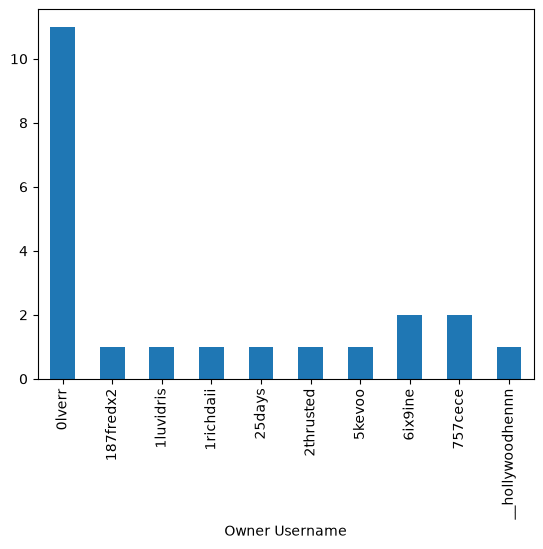

In [27]:
polls_by_account.head(10).plot(kind='bar')

<Axes: xlabel='Owner Username'>

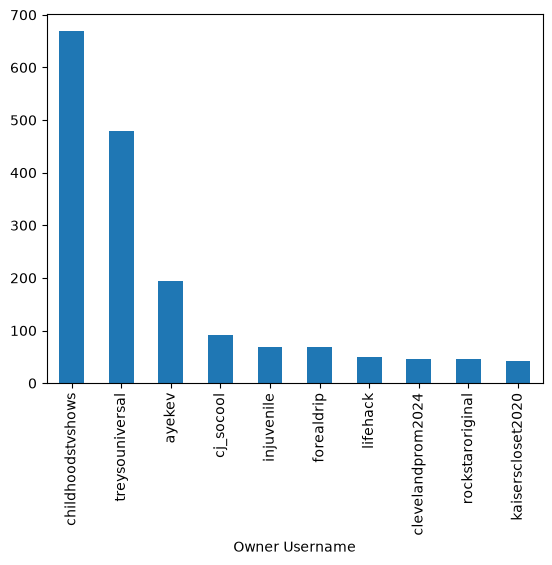

In [29]:
polls_by_account = polls_by_account.sort_values(ascending=False)

polls_by_account.head(10).plot(kind='bar')


In conclusion, my results show that my Instagram Story poll activity is different across accounts. A few accounts have more polls associated with them than others. The childhoodstvshows account had the most polls in my data, followed by treysouniversal and ayekev.

An alternative approach would be to compare this poll data with another type of Instagram activity. Another could be to look at the timestamps of the polls to see when I interact with Instagram Stories the most. Also, another limitation is that the data does not explain why some accounts have more polls associated with them. (Asked ChatGPT to help me with chart data)